In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Optimal Control, LQR, and Model Predictive Control

Dynamic programming (that section) solved the slippery lake by sweeping a table of sixteen state values until Bellman's optimality equation held at every cell, and every method since, from Q-learning to behavior cloning, has kept one table row per state. What happens when the state is a continuous vector $\mathbf{x}_t \in \mathbb{R}^d$ of positions, angles, and velocities, as in the vehicle of that section, and the action is a continuous control $\mathbf{u}_t \in \mathbb{R}^m$ that acts through known dynamics $\mathbf{x}_{t+1} = f(\mathbf{x}_t, \mathbf{u}_t)$? Grids do not scale: partitioning each of $d$ coordinates into $100$ bins produces $100^d$ cells, Bellman's *curse of dimensionality* [@BellmanDPBook].

Control theory solved this problem in continuous state and action spaces long before deep reinforcement learning, starting from an algebraic observation due to @Kalman.1960 . When the transition dynamics are linear in the state and control, and the one-step cost is quadratic in both, Bellman's backward dynamic programming preserves the quadratic form of the value function at every step. Instead of a table of $100^d$ entries, the exact value function $V_t(\mathbf{x}) = \mathbf{x}^\top \mathbf{P}_t \mathbf{x}$ is parameterized by a symmetric $d \times d$ matrix $\mathbf{P}_t$ with $d(d+1)/2$ independent numbers. The Bellman backup reduces to the *Riccati recursion*, and the optimal policy is a linear state-feedback law $\mathbf{u}_t^* = -\mathbf{K}_t \mathbf{x}_t$: the *Linear-Quadratic Regulator* (LQR) [@Kalman.1960; @Anderson.Moore.2007].

Most physical systems are nonlinear, and actuators saturate. Two ideas extend LQR to nonlinear continuous control and form the backbone of modern trajectory optimization and robotics [@Tedrake.2023; @Bertsekas.2025]. First, *iterative LQR* (iLQR) [@Li.Todorov.2004] repeatedly linearizes the nonlinear dynamics and quadratizes the cost around a candidate trajectory, solving a time-varying LQR problem in the backward pass to improve the trajectory in the forward pass. Second, *Model Predictive Control* (MPC) [@Rawlings.Mayne.Diehl.2017] turns finite-horizon trajectory optimization into a closed-loop policy: at every step $t$, it re-solves the control problem over a receding lookahead horizon from the current measured state $\mathbf{x}_t$, applies only the first control $\mathbf{u}_{t|t}^*$, and re-plans at step $t+1$. This section develops LQR, iLQR, and receding-horizon MPC, showing where local linear feedback suffices, where nonlinear energy pumping is required, and how MPC sets the stage for planning with learned neural dynamics in that section.

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## Linear-Quadratic Regulation

### State-Space Dynamics and Quadratic Costs

In control notation, a continuous state is written $\mathbf{x}_t \in \mathbb{R}^d$ and an action (or control input) is written $\mathbf{u}_t \in \mathbb{R}^m$. Whereas reinforcement learning maximizes a reward $r(\mathbf{x}_t, \mathbf{u}_t)$, optimal control minimizes a stage cost $c(\mathbf{x}_t, \mathbf{u}_t) = -r(\mathbf{x}_t, \mathbf{u}_t)$. A discrete-time linear system evolves as

$$\mathbf{x}_{t+1} = \mathbf{A}\mathbf{x}_t + \mathbf{B}\mathbf{u}_t,$$

where $\mathbf{A} \in \mathbb{R}^{d \times d}$ is the state-transition matrix and $\mathbf{B} \in \mathbb{R}^{d \times m}$ is the control-input matrix (the discrete-time counterpart of the linear ODEs in that section). The target state is the origin $\mathbf{x} = \mathbf{0}$. Over a finite horizon of $H$ steps, we minimize the total quadratic cost

$$J(\mathbf{x}_0, \mathbf{u}_{0:H-1}) = \sum_{t=0}^{H-1} \big(\mathbf{x}_t^\top \mathbf{Q}\mathbf{x}_t + \mathbf{u}_t^\top \mathbf{R}\mathbf{u}_t\big) + \mathbf{x}_H^\top \mathbf{Q}_H \mathbf{x}_H,$$

where $\mathbf{Q} \succeq \mathbf{0}$ and $\mathbf{Q}_H \succeq \mathbf{0}$ are symmetric positive-semidefinite $d \times d$ state-cost matrices, and $\mathbf{R} \succ \mathbf{0}$ is a symmetric positive-definite $m \times m$ control-cost matrix. Requiring $\mathbf{R} \succ \mathbf{0}$ ensures that large control efforts always carry a positive penalty, so the one-step minimization over $\mathbf{u}_t$ has a unique finite solution.

### Exact Continuous Dynamic Programming and the Riccati Recursion

Let $V_t(\mathbf{x})$ be the optimal cost-to-go from state $\mathbf{x}$ at step $t \in \{0, \ldots, H\}$. At the terminal step $t = H$, no control remains and $V_H(\mathbf{x}) = \mathbf{x}^\top \mathbf{P}_H \mathbf{x}$ with $\mathbf{P}_H = \mathbf{Q}_H$. Moving backward from $t+1$ to $t$, the finite-horizon form of Bellman's optimality equation (that section) states that

$$V_t(\mathbf{x}) = \min_{\mathbf{u} \in \mathbb{R}^m} \Big\{ \mathbf{x}^\top \mathbf{Q}\mathbf{x} + \mathbf{u}^\top \mathbf{R}\mathbf{u} + V_{t+1}(\mathbf{A}\mathbf{x} + \mathbf{B}\mathbf{u}) \Big\}.$$

Suppose by backward induction that $V_{t+1}(\mathbf{x}') = {\mathbf{x}'}^\top \mathbf{P}_{t+1} \mathbf{x}'$ for a symmetric positive-semidefinite matrix $\mathbf{P}_{t+1} \succeq \mathbf{0}$. Substituting $\mathbf{x}' = \mathbf{A}\mathbf{x} + \mathbf{B}\mathbf{u}$ expands the bracketed action-value function $Q_t(\mathbf{x}, \mathbf{u})$ into a strictly convex quadratic in $\mathbf{u}$:

$$
\begin{aligned}
Q_t(\mathbf{x}, \mathbf{u}) &= \mathbf{x}^\top(\mathbf{Q} + \mathbf{A}^\top \mathbf{P}_{t+1}\mathbf{A})\mathbf{x} + 2\mathbf{u}^\top \mathbf{B}^\top \mathbf{P}_{t+1}\mathbf{A}\mathbf{x} \\
&\quad + \mathbf{u}^\top(\mathbf{R} + \mathbf{B}^\top \mathbf{P}_{t+1}\mathbf{B})\mathbf{u}.
\end{aligned}
$$

Setting the gradient with respect to $\mathbf{u}$ to zero,

$$\nabla_{\mathbf{u}} Q_t(\mathbf{x}, \mathbf{u}) = 2(\mathbf{R} + \mathbf{B}^\top \mathbf{P}_{t+1}\mathbf{B})\mathbf{u} + 2\mathbf{B}^\top \mathbf{P}_{t+1}\mathbf{A}\mathbf{x} = \mathbf{0},$$

yields the unique optimal control in closed form:

$$\mathbf{u}_t^* = -\mathbf{K}_t \mathbf{x}_t, \qquad \mathbf{K}_t = (\mathbf{R} + \mathbf{B}^\top \mathbf{P}_{t+1}\mathbf{B})^{-1} \mathbf{B}^\top \mathbf{P}_{t+1}\mathbf{A}.$$

Substituting $\mathbf{u} = -\mathbf{K}_t \mathbf{x}$ back into $Q_t(\mathbf{x}, \mathbf{u})$ confirms that $V_t(\mathbf{x}) = \mathbf{x}^\top \mathbf{P}_t \mathbf{x}$ remains purely quadratic, where $\mathbf{P}_t$ obeys the backward *discrete-time Riccati recursion*:

$$
\begin{aligned}
\mathbf{P}_t &= \mathbf{Q} + \mathbf{A}^\top \mathbf{P}_{t+1}\mathbf{A} \\
&\quad - \mathbf{A}^\top \mathbf{P}_{t+1}\mathbf{B}(\mathbf{R} + \mathbf{B}^\top \mathbf{P}_{t+1}\mathbf{B})^{-1}\mathbf{B}^\top \mathbf{P}_{t+1}\mathbf{A}.
\end{aligned}
$$

The recursion runs backward once, from $\mathbf{P}_H = \mathbf{Q}_H$, and needs no state to do so. Running the system is then cheap: at each step the controller measures $\mathbf{x}_t$ and multiplies it by a stored gain, as the figure shows.

![LQR in closed loop. The controller multiplies the measured state $\mathbf{x}_t$ by the gain $-\mathbf{K}_t$, the system (the *plant*, in control terms) responds with the next state, and that state is measured in turn. All gains are computed by the backward Riccati recursion before the loop starts.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rl-lqr-loop.svg)

Three properties of the equation and the equation deserve emphasis:

1. **No curse of dimensionality:** Each Bellman backup replaces a maximization over an infinite action space $\mathbb{R}^m$ and all states $\mathbb{R}^d$ by $O(d^3 + m^3)$ matrix operations on $\mathbf{P}_{t+1}$.
2. **Linear feedback gain:** The optimal policy $\pi_t^*(\mathbf{x}) = -\mathbf{K}_t \mathbf{x}$ is linear in the state, and the gain matrix $\mathbf{K}_t \in \mathbb{R}^{m \times d}$ depends only on $(\mathbf{A}, \mathbf{B}, \mathbf{Q}, \mathbf{R})$, not on the initial state $\mathbf{x}_0$.
3. **Certainty equivalence:** Even if zero-mean independent noise $\mathbf{w}_t$ with covariance $\boldsymbol{\Sigma}$ is added to the transition ($\mathbf{x}_{t+1} = \mathbf{A}\mathbf{x}_t + \mathbf{B}\mathbf{u}_t + \mathbf{w}_t$), the cross term $\mathbb{E}[\mathbf{w}_t^\top \mathbf{P}_{t+1}(\mathbf{A}\mathbf{x}_t + \mathbf{B}\mathbf{u}_t)]$ vanishes, adding only the constant $\textrm{tr}(\mathbf{P}_{t+1}\boldsymbol{\Sigma})$ to the value function while leaving the optimal feedback matrix $\mathbf{K}_t$ unchanged (exercise 2).

As the horizon $H \to \infty$ (under standard controllability and observability conditions), $\mathbf{P}_t$ converges to a stationary solution $\mathbf{P}_\infty$ of the *Discrete Algebraic Riccati Equation* (DARE), and the time-invariant controller $\mathbf{u}_t = -\mathbf{K}_\infty \mathbf{x}_t$ stabilizes the closed-loop dynamics $\mathbf{x}_{t+1} = (\mathbf{A} - \mathbf{B}\mathbf{K}_\infty)\mathbf{x}_t$ so that every eigenvalue of $\mathbf{A} - \mathbf{B}\mathbf{K}_\infty$ lies strictly inside the unit circle, $\rho(\mathbf{A} - \mathbf{B}\mathbf{K}_\infty) < 1$.

### The Double Integrator

We test `riccati_lqr` on the vehicle from the state-augmentation example of that section: a unit mass moving along a line with state $\mathbf{x}_t = (p_t, v_t)^\top$ (position and velocity), control $u_t$ (acceleration), and time step $\Delta t = 0.1$. By Newton's laws, $p_{t+1} = p_t + v_t \Delta t + \frac{1}{2} u_t \Delta t^2$ and $v_{t+1} = v_t + u_t \Delta t$. We penalize position and velocity deviations with $\mathbf{Q} = \textrm{diag}(1.0, 0.1)$ and sweep the control-effort weight $r_u \in \{0.01, 0.10, 1.00\}$ in $\mathbf{R} = [r_u]$:

In [2]:
def riccati_lqr(A, B, Q, R, H=100):
    """Backward Riccati recursion for horizon H; returns (Ps, Ks) from t=0..H."""
    P = Q.copy()
    Ps, Ks = [P], []
    for _ in range(H):
        BtP = B.T @ P
        K = np.linalg.solve(R + BtP @ B, BtP @ A)
        P = Q + A.T @ P @ (A - B @ K)
        Ks.append(K)
        Ps.append(P)
    return Ps[::-1], Ks[::-1]

dt = 0.1
A_di = np.array([[1.0, dt], [0.0, 1.0]])
B_di = np.array([[0.5 * dt**2], [dt]])
Q_di = np.diag([1.0, 0.1])

for ru in (0.01, 0.10, 1.00):
    Ps, Ks = riccati_lqr(A_di, B_di, Q_di, np.array([[ru]]), H=100)
    K_inf, P_inf = Ks[0][0], Ps[0]
    rho = np.abs(np.linalg.eigvals(A_di - B_di @ Ks[0])).max()
    print(f'R={ru:4.2f}  K_inf=[{K_inf[0]:5.3f}, {K_inf[1]:5.3f}]  '
          f'P_00={P_inf[0, 0]:5.2f}  rho(A - B K)={rho:.3f}')

R=0.01  K_inf=[7.613, 4.585]  P_00= 6.02  rho(A - B K)=0.761
R=0.10  K_inf=[2.762, 2.508]  P_00= 9.08  rho(A - B K)=0.874
R=1.00  K_inf=[0.930, 1.395]  P_00=15.00  rho(A - B K)=0.930


We can also plot the closed-loop position trajectories $p_t$ starting from $\mathbf{x}_0 = (1, 0)^\top$ under the three control-effort penalties:

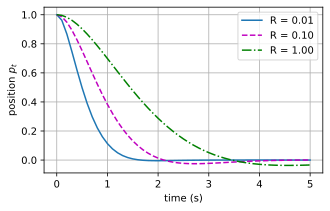

In [3]:
trajs, steps_di = [], np.arange(51) * dt
for ru in (0.01, 0.10, 1.00):
    _, Ks = riccati_lqr(A_di, B_di, Q_di, np.array([[ru]]), H=100)
    x, xs_di = np.array([1.0, 0.0]), [1.0]
    for _ in range(50):
        x = (A_di - B_di @ Ks[0]) @ x
        xs_di.append(x[0])
    trajs.append(xs_di)
d2l.plot(steps_di, trajs, 'time (s)', 'position $p_t$',
         legend=['R = 0.01', 'R = 0.10', 'R = 1.00'], figsize=(5, 3))

Look at the two components of the stationary feedback law $u_t^* = -k_p p_t - k_v v_t$: dynamic programming has automatically derived a *proportional-derivative* (PD) controller, pushing back against the position error $p_t$ with gain $k_p$ and damping the velocity $v_t$ with gain $k_v$. When control effort is cheap ($R = 0.01$), LQR chooses aggressive gains $\mathbf{K}_\infty = [7.613, 4.585]$ that contract the state norm at rate $\rho(\mathbf{A} - \mathbf{B}\mathbf{K}_\infty) = 0.761$ per step; when control effort is expensive ($R = 1.00$), it uses gentle accelerations $\mathbf{K}_\infty = [0.930, 1.395]$ with contraction rate $\rho = 0.930$ and a higher cumulative cost $V_0(\mathbf{x}_0) = \mathbf{x}_0^\top \mathbf{P}_\infty \mathbf{x}_0$ ($P_{00} = 15.00$ vs. $6.02$).

## Linearizing a Nonlinear System Around an Equilibrium

### Analytical Linearization of `Pendulum-v1`

Now consider a physical benchmark that will accompany us through the rest of this chapter and that section: the inverted pendulum (`Pendulum-v1`). A rigid rod of mass $m = 1$ and length $l = 1$ is pivoted at one end under gravity $g = 10$ and driven by a bounded motor torque $u_t \in [-2, 2]$. Its continuous state is $\mathbf{x}_t = (\vartheta_t, \dot\vartheta_t)^\top$, where $\vartheta_t$ is the angle measured from the upright vertical ($\vartheta = 0$ upright, $\vartheta = \pi$ hanging straight down) and $\dot\vartheta_t \in [-8, 8]$ is the angular velocity. Because the peak gravitational torque at the horizontal ($\vartheta = \pi/2$) is $mgl/2 = 5 > 2$, the motor is *underactuated*: it cannot lift the rod directly from the bottom to the top in a single push. Over one simulator step of $\Delta t = 0.05\text{ s}$, the semi-implicit Euler transition $\mathbf{x}_{t+1} = f(\mathbf{x}_t, u_t)$ is

$$
\begin{aligned}
\dot\vartheta_{t+1} &= \dot\vartheta_t + \Big(\frac{3g}{2l}\sin\vartheta_t + \frac{3}{ml^2}u_t\Big)\Delta t, \\
\vartheta_{t+1} &= \vartheta_t + \dot\vartheta_{t+1}\Delta t,
\end{aligned}
$$

with angular velocity clipped to $[-8, 8]$. Each step incurs the quadratic stage cost $c(\vartheta_t, \dot\vartheta_t, u_t) = \vartheta_t^2 + 0.1\,\dot\vartheta_t^2 + 0.001\,u_t^2$ (with $\vartheta_t$ wrapped to $[-\pi, \pi]$, corresponding to $\mathbf{Q} = \textrm{diag}(1.0, 0.1)$ and $\mathbf{R} = [[0.001]]$), or equivalently emits the reward $r_t = -c(\vartheta_t, \dot\vartheta_t, u_t)$. Standard benchmark episodes run for $200$ steps ($10\text{ s}$): an uncontrolled pendulum scores around $-1{,}200$ to $-1{,}500$, whereas a controller that swings the rod up and balances it upright averages about $-200$ or better over the benchmark's random starting states. Here we plan directly with the known equations of motion the equation; that section, that section, and that section will return to this exact pendulum benchmark when the agent must act or learn a dynamics model without knowing the physics.

The upright posture $\mathbf{x}^* = (0, 0)^\top$ with zero torque $u^* = 0$ is a fixed point, $f(\mathbf{x}^*, u^*) = \mathbf{x}^*$. Near any reference pair $(\bar{\mathbf{x}}, \bar{u})$, a first-order Taylor expansion approximates the nonlinear transition by a local linear model in the deviations $\delta\mathbf{x}_t = \mathbf{x}_t - \bar{\mathbf{x}}$ and $\delta u_t = u_t - \bar{u}$:

$$
\begin{aligned}
f(\mathbf{x}_t, u_t) - f(\bar{\mathbf{x}}, \bar{u}) &\approx \mathbf{A}(\bar{\mathbf{x}}, \bar{u})\,\delta\mathbf{x}_t + \mathbf{B}(\bar{\mathbf{x}}, \bar{u})\,\delta u_t, \\
\mathbf{A} &= \frac{\partial f}{\partial \mathbf{x}}(\bar{\mathbf{x}}, \bar{u}), \qquad \mathbf{B} = \frac{\partial f}{\partial u}(\bar{\mathbf{x}}, \bar{u}).
\end{aligned}
$$

Differentiating the equation with respect to $(\vartheta_t, \dot\vartheta_t)$ and $u_t$ yields $\partial\dot\vartheta_{t+1}/\partial\vartheta_t = \frac{3g}{2l}\cos(\vartheta_t)\Delta t$ and $\partial\dot\vartheta_{t+1}/\partial u_t = \frac{3}{ml^2}\Delta t$:

In [4]:
def pendulum_jacobians(th, dt=0.05, g=10.0):
    """Exact Jacobians (A, B) of Pendulum-v1 at angle th."""
    dthdot_dth = 1.5 * g * np.cos(th) * dt
    dthdot_du = 3.0 * dt
    A = np.array([[1.0 + dthdot_dth * dt, dt], [dthdot_dth, 1.0]])
    B = np.array([[dthdot_du * dt], [dthdot_du]])
    return A, B

A_p, B_p = pendulum_jacobians(0.0)
Q_p, R_p = np.diag([1.0, 0.1]), np.array([[0.001]])
Ps_p, Ks_p = riccati_lqr(A_p, B_p, Q_p, R_p, H=200)
K_lqr = Ks_p[0][0]
eigs_open = np.linalg.eigvals(A_p).real
eigs_closed = np.linalg.eigvals(A_p - B_p @ Ks_p[0]).real
print(f'A at upright:\n{A_p}')
print(f'open-loop eigenvalues:   {eigs_open[0]:.4f}, {eigs_open[1]:.4f}')
print(f'LQR gain K_inf:          [{K_lqr[0]:.3f}, {K_lqr[1]:.3f}]')
print(f'closed-loop eigenvalues: {eigs_closed[0]:.4f}, {eigs_closed[1]:.4f}')

A at upright:
[[1.0375 0.05  ]
 [0.75   1.    ]]
open-loop eigenvalues:   1.2133, 0.8242
LQR gain K_inf:          [19.693, 5.263]
closed-loop eigenvalues: 0.8537, 0.2467


At the upright fixed point, the open-loop Jacobian $\mathbf{A}$ has an unstable eigenvalue $\lambda_1 = 1.2133 > 1$: any small tilt grows exponentially at over $21\%$ per step, as seen in the phase portrait of that section. Solving the Riccati recursion with `Pendulum-v1`'s cost matrices $\mathbf{Q} = \textrm{diag}(1, 0.1)$ and $\mathbf{R} = [[0.001]]$ produces the feedback gain $\mathbf{K}_\infty = [19.693, 5.263]$, which pulls both closed-loop eigenvalues inside the unit circle ($\lambda_1 = 0.8537, \lambda_2 = 0.2467$).

### Torque Saturation and the Basin of Attraction

How far from the top can this linear controller catch the pendulum when the motor torque is clipped to $[-2, 2]$? The gravitational torque pulling the pendulum down is $\frac{1}{2}mgl\sin\vartheta = 5\sin\vartheta$, whereas the motor supplies at most $|u| = 2$. Once $|\vartheta| > \arcsin(2/5) \approx 0.412\text{ rad}$ ($23.6^\circ$), gravity exceeds the peak holding torque of the motor. We test the clipped LQR policy $u_t = \textrm{clip}(-\mathbf{K}_\infty \mathbf{x}_t, -2, 2)$ on the full nonlinear pendulum from five starting angles $\vartheta_0$ at rest:

In [5]:
def wrap(th):
    return ((th + np.pi) % (2 * np.pi)) - np.pi

def pendulum_step(x, u, dt=0.05, g=10.0):
    """One step of nonlinear Pendulum-v1 dynamics in (theta, thetadot)."""
    th, thdot = x
    u_c = float(np.clip(u, -2.0, 2.0))
    newthdot = float(np.clip(thdot + (1.5 * g * np.sin(th) + 3.0 * u_c) * dt,
                             -8.0, 8.0))
    newth = th + newthdot * dt
    cost = wrap(th)**2 + 0.1 * thdot**2 + 0.001 * u_c**2
    return np.array([newth, newthdot]), cost

for th0 in (0.20, 0.40, 0.50, 0.60, np.pi):
    x, total_cost = np.array([th0, 0.0]), 0.0
    for _ in range(200):
        u = -(K_lqr[0] * wrap(x[0]) + K_lqr[1] * x[1])
        x, c = pendulum_step(x, u)
        total_cost += c
    print(f'th0={th0:4.2f} rad: 200-step return={-total_cost:8.2f}, '
          f'final theta={wrap(x[0]):+6.3f} rad')

th0=0.20 rad: 200-step return=   -0.32, final theta=+0.000 rad
th0=0.40 rad: 200-step return=   -2.97, final theta=+0.000 rad
th0=0.50 rad: 200-step return= -770.94, final theta=+2.592 rad
th0=0.60 rad: 200-step return= -546.37, final theta=+0.001 rad
th0=3.14 rad: 200-step return=-1471.86, final theta=-2.249 rad


Inside the static holding threshold ($\vartheta_0 = 0.20$ and $0.40\text{ rad}$), linear LQR drives the pendulum straight to upright ($\vartheta_{200} = 0.000$) with near-zero cost (returns $-0.32$ and $-2.97$). Just outside that threshold ($\vartheta_0 = 0.50\text{ rad}$), full negative torque $u = -2$ cannot arrest the fall, and the rod is still swinging through the bottom after 200 steps (return $-770.94$). Beyond the threshold the outcome is no longer monotone in $\vartheta_0$. From $0.60\text{ rad}$ the rod falls just the same, but after a few more swings it happens to come up slowly enough for the clipped controller to catch it (return $-546.37$). This is luck, not control. From the bottom ($\vartheta_0 = \pi$) the linear controller earns $-1471.86$ and never reaches the top. Because the motor is underactuated ($u_{\max} = 2 < 5$), swinging up from $\vartheta_0 = \pi$ requires *energy pumping*: pushing in one direction, reversing torque as the pendulum swings back through the bottom to build kinetic and potential energy, and only switching to upright stabilization once the rod climbs into the top catch basin.

## Nonlinear Trajectory Optimization via Iterative LQR

### Linearizing Along a Trajectory

A single linearization at $(\mathbf{0}, 0)$ knows nothing about the nonlinear sin$(\vartheta)$ curvature along a swing from $\vartheta_0 = \pi$. *Iterative Linear-Quadratic Regulation* (iLQR) [@Li.Todorov.2004], a Gauss–Newton variant of Differential Dynamic Programming [@Mayne.1966], instead linearizes around an entire nominal trajectory.

To enforce the torque bound $u_t \in [-2, 2]$ smoothly without hard-clipping kinks, we parameterize $u_t = 2\tanh(v_t)$ via an unconstrained control variable $v_t \in \mathbb{R}$. Given any nominal control sequence $\bar{v}_{0:H-1}$ and its forward rollout $\bar{\mathbf{x}}_{0:H}$ under the true nonlinear dynamics $\mathbf{x}_{t+1} = f(\mathbf{x}_t, v_t)$ (without the velocity clip, which the swing-up below never reaches), each iteration of iLQR performs two passes:

1. **Backward Riccati pass along $(\bar{\mathbf{x}}_{0:H}, \bar{v}_{0:H-1})$:** At each step $t = H-1, \ldots, 0$, compute the local Jacobians $\mathbf{A}_t = \frac{\partial f}{\partial \mathbf{x}}(\bar{\mathbf{x}}_t, \bar{v}_t)$ and $\mathbf{B}_t = \frac{\partial f}{\partial v}(\bar{\mathbf{x}}_t, \bar{v}_t)$, and form a second-order Taylor approximation of the action-value perturbation $\delta Q_t(\delta\mathbf{x}_t, \delta v_t)$ from the stage cost gradients $(\boldsymbol{\ell}_{\mathbf{x},t}, \ell_{v,t})$, Hessians $(\mathbf{L}_{\mathbf{x}\mathbf{x},t}, \ell_{vv,t})$, and the next step's value gradient $\mathbf{v}_{\mathbf{x},t+1}$ and Hessian $\mathbf{V}_{\mathbf{x}\mathbf{x},t+1}$:

   $$
   \begin{aligned}
   \mathbf{q}_{\mathbf{x},t} &= \boldsymbol{\ell}_{\mathbf{x},t} + \mathbf{A}_t^\top \mathbf{v}_{\mathbf{x},t+1}, \qquad q_{v,t} = \ell_{v,t} + \mathbf{B}_t^\top \mathbf{v}_{\mathbf{x},t+1}, \\
   \mathbf{Q}_{\mathbf{x}\mathbf{x},t} &= \mathbf{L}_{\mathbf{x}\mathbf{x},t} + \mathbf{A}_t^\top \mathbf{V}_{\mathbf{x}\mathbf{x},t+1}\mathbf{A}_t, \qquad \mathbf{q}_{v\mathbf{x},t} = \mathbf{B}_t^\top \mathbf{V}_{\mathbf{x}\mathbf{x},t+1}\mathbf{A}_t, \\
   q_{vv,t} &= \ell_{vv,t} + \mu + \mathbf{B}_t^\top \mathbf{V}_{\mathbf{x}\mathbf{x},t+1}\mathbf{B}_t,
   \end{aligned}
   $$

   where $\mu > 0$ is a Levenberg–Marquardt damping term. Minimizing over $\delta v_t$ gives an open-loop feedforward step $k_t = -q_{v,t}/q_{vv,t}$ and a local linear feedback gain $\mathbf{K}_t = -\mathbf{q}_{v\mathbf{x},t}/q_{vv,t}$.
2. **Forward rollout with backtracking line search:** Because the linear model is only accurate near $(\bar{\mathbf{x}}_t, \bar{v}_t)$, we roll out the *true nonlinear dynamics* with step size $\alpha \in \{1, 1/2, 1/4, \ldots\}$,

   $$
   \begin{aligned}
   v_t^{\textrm{new}} &= \bar{v}_t + \alpha\, k_t + \mathbf{K}_t(\mathbf{x}_t^{\textrm{new}} - \bar{\mathbf{x}}_t), \\
   \mathbf{x}_{t+1}^{\textrm{new}} &= f(\mathbf{x}_t^{\textrm{new}}, v_t^{\textrm{new}}),
   \end{aligned}
   $$

   and accept the first $\alpha$ that decreases the true nonlinear trajectory cost.

One design detail of the trajectory cost is instructive. To pump energy from $\vartheta_0 = \pi$, the pendulum must first swing to $\vartheta > \pi$ on the opposite side before whipping back toward $\vartheta = 0$. If we place a heavy quadratic penalty $\vartheta_t^2$ on every early step $t$, a local gradient method refuses to swing away from $0$ because $\vartheta_t^2$ increases during the back-swing. Weighting the state cost lightly during the swing phase ($q_{\textrm{run}} = 0.02$ for $t < H - 20$) and heavily during the final capture window ($q_T = 100$ for $t \geq H - 20$) lets iLQR use the early steps to pump energy and the final steps to lock the rod at $(\vartheta, \dot\vartheta) = (0, 0)$:

t= 0  theta= 3.1416  thetadot= 0.0000  u=-1.782
t=10  theta= 2.6515  thetadot=-1.0260  u=+0.965
t=20  theta= 3.5453  thetadot= 3.3225  u=+1.681
t=30  theta= 4.0383  thetadot=-2.6013  u=-1.807
t=40  theta= 1.5668  thetadot=-4.4402  u=-1.832
t=50  theta= 0.3746  thetadot=-1.3417  u=-1.209
t=60  theta= 0.0009  thetadot=-0.0132  u=+0.066
t=70  theta= 0.0002  thetadot=-0.0006  u=-0.000
t=80  theta= 0.0001  thetadot=-0.0000  u=+0.000


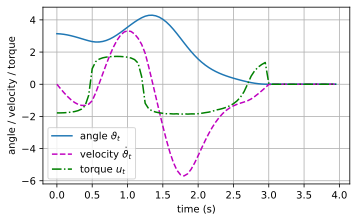

In [6]:
def step_tanh(x, v, dt=0.05, g=10.0):
    """Nonlinear step and analytical Jacobians (A_t, B_t) for u = 2 tanh(v)."""
    th, thdot = x[0], x[1]
    th_v = np.tanh(v)
    u = 2.0 * th_v
    du_dv = 2.0 * (1.0 - th_v**2)
    newthdot = thdot + (1.5 * g * np.sin(th) + 3.0 * u) * dt
    newth = th + newthdot * dt
    dthdot_dth = 1.5 * g * np.cos(th) * dt
    dthdot_dv = 3.0 * dt * du_dv
    A = np.array([[1.0 + dthdot_dth * dt, dt], [dthdot_dth, 1.0]])
    B = np.array([[dthdot_dv * dt], [dthdot_dv]])
    return np.array([newth, newthdot]), A, B, u

def ilqr_swingup(x0, H=80, iters=35, q_run=0.02, r_v=0.02, q_T=100.0,
                 vs_init=None):
    """iLQR trajectory optimization from x0 over horizon H."""
    vs = (np.array(vs_init, dtype=float) if vs_init is not None
          else np.array([0.2 if t < 15 else 0.0 for t in range(H)]))
    Q_base = np.diag([1.0, 0.1])
    for _ in range(iters):
        xs, As, Bs, us, cost = [np.array(x0, dtype=float)], [], [], [], 0.0
        for t in range(H):
            x_next, A, B, u = step_tanh(xs[-1], vs[t])
            As.append(A); Bs.append(B); us.append(u)
            w = q_T if t >= H - 20 else q_run
            cost += w * (xs[-1] @ Q_base @ xs[-1]) + r_v * vs[t]**2
            xs.append(x_next)
        cost += q_T * (xs[-1] @ Q_base @ xs[-1])

        Vx = 2.0 * q_T * (Q_base @ xs[-1])
        Vxx = 2.0 * q_T * Q_base
        ks, Ks = np.zeros(H), np.zeros((H, 2))
        for t in range(H - 1, -1, -1):
            w = q_T if t >= H - 20 else q_run
            A, B = As[t], Bs[t]
            Qx = 2.0 * w * (Q_base @ xs[t]) + A.T @ Vx
            Qv = 2.0 * r_v * vs[t] + (B.T @ Vx).item()
            Qxx = 2.0 * w * Q_base + A.T @ Vxx @ A
            Qvv = 2.0 * r_v + 1e-2 + (B.T @ Vxx @ B).item()
            Qvx = (B.T @ Vxx @ A).ravel()
            ks[t], Ks[t] = -Qv / Qvv, -Qvx / Qvv
            Vx = Qx + Qvx * ks[t]
            Vxx = Qxx + np.outer(Qvx, Ks[t])

        for alpha in (1.0, 0.5, 0.25, 0.1, 0.03):
            x_new, vs_new, c_new = np.array(x0, dtype=float), np.zeros(H), 0.0
            for t in range(H):
                v_t = vs[t] + alpha * ks[t] + Ks[t] @ (x_new - xs[t])
                vs_new[t] = v_t
                w = q_T if t >= H - 20 else q_run
                c_new += w * (x_new @ Q_base @ x_new) + r_v * v_t**2
                x_new, _, _, _ = step_tanh(x_new, v_t)
            c_new += q_T * (x_new @ Q_base @ x_new)
            if c_new < cost:
                vs = vs_new
                break
    return np.array(xs), np.array(us), vs, Ks, cost

xs_nom, us_nom, vs_nom, Ks_nom, _ = ilqr_swingup([np.pi, 0.0], H=80, iters=35)
for t in range(0, 81, 10):
    u_t = us_nom[t] if t < 80 else 0.0
    print(f't={t:2d}  theta={xs_nom[t, 0]:7.4f}  '
          f'thetadot={xs_nom[t, 1]:7.4f}  u={u_t:+6.3f}')
d2l.plot(np.arange(80) * 0.05, [xs_nom[:-1, 0], xs_nom[:-1, 1], us_nom],
         'time (s)', 'angle / velocity / torque',
         legend=[r'angle $\vartheta_t$', r'velocity $\dot{\vartheta}_t$',
                 r'torque $u_t$'], figsize=(5.5, 3.2))

Look at the trajectory that iLQR discovers in 35 iterations from the bottom $(\pi, 0)$:

- **Steps 0 to 10 (initial back-swing):** It pushes left ($u_0 = -1.782$) to $\vartheta_{10} = 2.652\text{ rad}$.
- **Steps 10 to 30 (energy pump):** It reverses torque ($u_{10} = +0.965 \to u_{20} = +1.681$), driving the pendulum through the bottom to $\vartheta_{30} = 4.038\text{ rad}$ on the other side to store gravitational potential energy.
- **Steps 30 to 60 (whip and catch):** It reverses torque again ($u_{30} = -1.807 \to u_{40} = -1.832$), passing the bottom at up to $5.7\text{ rad/s}$ and still moving at $\dot\vartheta_{40} = -4.440\text{ rad/s}$ as it climbs past the horizontal ($\vartheta_{40} = 1.567\text{ rad}$) into the upright catch basin ($\vartheta_{50} = 0.375\text{ rad}$) and brakes smoothly to rest at the top ($\vartheta_{60} = 0.0009\text{ rad}$, $\vartheta_{80} = 0.0001\text{ rad}$, $u_{80} = 0.000$).

This plan is a local optimum, and we should not mistake it for the best swing-up. Each iLQR iteration improves the trajectory it was given, so the result depends on the initial control sequence. `ilqr_swingup` starts from a small push over the first 15 steps ($\bar{v}_t = 0.2$) and nothing after, and with a fixed damping $\mu$. The push matters: started from $\bar{v} = 0$, the same 35 iterations do not bring the rod to rest at the top. The dependence on the initial guess returns below, where it decides whether a controller recovers from a knock.

## Receding-Horizon Model Predictive Control

### Open-Loop Plans, Local Feedback Tubes, and Online Re-Planning

An optimal trajectory $(\bar{\mathbf{x}}_{0:H}, \bar{u}_{0:H-1})$ is not yet a robust controller. We can execute the plan in three ways:

1. **Open-loop execution:** Apply the precomputed sequence $\bar{u}_t$ blind to the actual state $\mathbf{x}_t$. Because the upright posture is an unstable saddle, even a small disturbance or numerical drift pushes the trajectory off course.
2. **Time-varying LQR (TV-LQR) tracking:** Use the local feedback matrices $\mathbf{K}_t$ computed during the final backward pass of iLQR, applying $v_t = \bar{v}_t + \mathbf{K}_t(\mathbf{x}_t - \bar{\mathbf{x}}_t)$. This surrounds the nominal trajectory with a local linear feedback tube at zero online planning cost, but fails if a strong knock pushes $\mathbf{x}_t$ out of the tube into a region where a fresh swing-up pump is needed.
3. **Receding-horizon Model Predictive Control (MPC):** At every time step $t$, observe the true state $\mathbf{x}_t$, re-solve the finite-horizon control problem over a lookahead window starting from $\mathbf{x}_t$ (warm-started by shifting the previous step's plan by one step), apply *only the first control* $u_{t|t}^*$, and repeat at $t+1$ [@Rawlings.Mayne.Diehl.2017].

Our `mpc_action` settles two details of the third scheme. The first is the length of the window. The shifted plan is one step shorter than the plan before it, so the window starts at the 80 steps of the nominal plan and shrinks with it. Once `H_min` $= 25$ steps are left, the plan is padded with zeros and the window recedes at that length. The second detail is what to do when the warm start fails. Because iLQR is a local method, a warm-started plan stays near the old trajectory even when that trajectory no longer leads to the top. If the re-optimized plan ends more than $0.2\text{ rad}$ from upright, `mpc_action` discards it and plans a fresh swing-up over `H_mpc` $= 60$ steps ($3\text{ s}$), from the initial push that `ilqr_swingup` uses by default.

We compare all three controllers over $T = 120$ steps from $\mathbf{x}_0 = (\pi, 0)$ when an external angular-velocity impulse $\Delta\dot\vartheta \in \{0.0, +0.5, +2.2\}\text{ rad/s}$ strikes the pendulum at step $t = 45$, just as it climbs past the horizontal toward the upright catch basin:

In [ ]:
T = 120
xs_pad = np.vstack([xs_nom, np.zeros((T - 80, 2))])
vs_pad = np.concatenate([vs_nom, np.zeros(T - 80)])
us_pad = np.concatenate([us_nom, np.zeros(T - 80)])
Ks_pad = np.vstack([Ks_nom, np.tile(Ks_nom[-1], (T - 80, 1))])

def mpc_action(x, vs_warm, H_mpc=60, H_min=25):
    """One MPC step: re-optimize the shifted plan (at least H_min steps) from x;
    if it no longer ends at the top, plan afresh over H_mpc steps."""
    H = max(H_min, len(vs_warm))
    warm = np.concatenate([vs_warm, np.zeros(H)])[:H]
    xs_w, us_w, vs_w, _, _ = ilqr_swingup(x, H=H, iters=18, vs_init=warm)
    if abs(xs_w[-1, 0]) > 0.2:   # warm plan missed the top: re-seed
        _, us_s, vs_s, _, _ = ilqr_swingup(x, H=H_mpc, iters=25)
        return us_s[0], vs_s[0], vs_s[1:]
    return us_w[0], vs_w[0], vs_w[1:]

for impulse in (0.0, 0.5, 2.2):
    x_ol, x_tv, x_mpc = [np.array([np.pi, 0.0]) for _ in range(3)]
    ret_ol = ret_tv = ret_mpc = 0.0
    th_ol, th_tv, th_mpc = [], [], []
    vs_warm = vs_nom.copy()
    for t in range(T):
        if t == 45:
            for x in (x_ol, x_tv, x_mpc):
                x[1] += impulse
        th_ol.append(wrap(x_ol[0]))
        th_tv.append(wrap(x_tv[0]))
        th_mpc.append(wrap(x_mpc[0]))
        # 1. Open-loop
        ret_ol -= wrap(x_ol[0])**2 + 0.1 * x_ol[1]**2 + 0.001 * us_pad[t]**2
        x_ol, _, _, _ = step_tanh(x_ol, vs_pad[t])
        # 2. Time-varying LQR tracking
        v_tv = vs_pad[t] + Ks_pad[t] @ (x_tv - xs_pad[t])
        u_tv = 2.0 * np.tanh(v_tv)
        ret_tv -= wrap(x_tv[0])**2 + 0.1 * x_tv[1]**2 + 0.001 * u_tv**2
        x_tv, _, _, _ = step_tanh(x_tv, v_tv)
        # 3. Receding-horizon MPC
        u_m, v_m, vs_warm = mpc_action(x_mpc, vs_warm)
        ret_mpc -= wrap(x_mpc[0])**2 + 0.1 * x_mpc[1]**2 + 0.001 * u_m**2
        x_mpc, _, _, _ = step_tanh(x_mpc, v_m)
    print(f'impulse={impulse:+.1f} rad/s at t=45:')
    print(f'  Open-loop:  final theta={wrap(x_ol[0]):+6.3f}, return={ret_ol:6.1f}')
    print(f'  TV-LQR:     final theta={wrap(x_tv[0]):+6.3f}, return={ret_tv:6.1f}')
    print(f'  MPC (iLQR): final theta={wrap(x_mpc[0]):+6.3f}, return={ret_mpc:6.1f}')
d2l.plot(np.arange(T) * 0.05, [th_ol, th_tv, th_mpc],
         'time (s)', r'wrapped angle $\vartheta_t$ (rad)',
         legend=['Open-loop', 'TV-LQR', 'MPC (iLQR)'], figsize=(5.5, 3.2))

the figure places the three stages of this section side by side: the local LQR value contours and torque-saturation boundary around the upright equilibrium, the iLQR energy-pumping trajectory in the $(\vartheta, \dot\vartheta)$ phase plane, and the disturbance-rejection trajectories under the strong impulse $\Delta\dot\vartheta = +2.2\text{ rad/s}$ at $t = 45$.

![Optimal control from local LQR to receding-horizon MPC. (a) Upright LQR cost-to-go contours $V_\infty(\mathbf{x}) = \mathbf{x}^\top\mathbf{P}_\infty\mathbf{x}$ and the static holding boundary $|\vartheta| \leq \arcsin(2/5) \approx 0.412\text{ rad}$ (dotted): starting from $\vartheta_0 = 0.40\text{ rad}$ converges to the origin (blue), whereas $\vartheta_0 = 0.50\text{ rad}$ saturates the motor torque $|u| \leq 2$ and falls away (orange dashed). (b) The 80-step iLQR swing-up trajectory in the $(\vartheta, \dot\vartheta)$ phase plane, pumping from $(\pi, 0)$ to $\vartheta_{30} = 4.04\text{ rad}$ before whipping through the bottom to the upright equilibrium $(0, 0)$. (c) Wrapped angle $\vartheta_t$ when an impulse $\Delta\dot\vartheta = +2.2\text{ rad/s}$ strikes at $t = 45$ ($2.25\text{ s}$, vertical dotted line): open-loop and TV-LQR fail, while receding-horizon MPC plans a new swing-up and returns to $\vartheta = 0$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rl-optimal-control.svg)

The three disturbance levels on our pendulum benchmark separate the three controllers cleanly:

- **No disturbance ($\Delta\dot\vartheta = 0.0$):** All three swing the pendulum up, earning returns between $-332$ and $-334$ over the 120 steps. These lie below the $-200$ quoted for the benchmark, for two reasons. We start from the bottom, the worst state, whereas the benchmark averages over random starts. And iLQR minimizes its own trajectory cost, with a light state weight during the swing, not the pendulum reward that scores the return. Over the final 40 steps after $t=80$, open-loop begins to drift to $\vartheta_{120} = +0.075\text{ rad}$ at the unstable saddle, while TV-LQR and MPC hold $\vartheta_{120} = 0.000\text{ rad}$.
- **Moderate disturbance ($\Delta\dot\vartheta = +0.5\text{ rad/s}$):** Open-loop execution is knocked off its precomputed schedule, falls back down, and ends at $\vartheta_{120} = -2.939\text{ rad}$ (return $-502.3$). Both TV-LQR ($\vartheta_{120} = -0.001\text{ rad}$, return $-333.9$) and MPC ($\vartheta_{120} = +0.000\text{ rad}$, return $-331.7$) absorb the push and lock the rod upright.
- **Strong disturbance ($\Delta\dot\vartheta = +2.2\text{ rad/s}$):** The knock arrests the upward climb and sends the pendulum falling back toward the bottom. TV-LQR's linear feedback around the old nominal trajectory saturates its torque and fails ($\vartheta_{120} = +1.959\text{ rad}$, return $-797.9$), because recovering requires a new swing-up pump that does not exist in a linear neighborhood of the old trajectory. MPC restores the pendulum to the upright equilibrium ($\vartheta_{120} = 0.000\text{ rad}$, return $-558.2$), and it owes this to the re-seed rule. At the step of the knock the warm-started plan misses the top, so `mpc_action` plans a fresh swing-up from the post-disturbance state and follows it from there. Re-planning from the warm start alone would not recover, because the warm-started plan stays near the old trajectory.

### From Classical Control to Reinforcement Learning

the table summarizes the dictionary between classical optimal control and reinforcement learning, and shows how the upcoming sections of this chapter and that section relax each assumption of LQR and iLQR:

<!-- tbl-caption:The bridge between classical optimal control and reinforcement learning. -->

| Concept | Classical Optimal Control | Reinforcement Learning |
|:--|:---|:---|
| Variables | state $\mathbf{x}_t \in \mathbb{R}^d$, control $\mathbf{u}_t \in \mathbb{R}^m$ | state $s_t \in \mathcal{S}$, action $a_t \in \mathcal{A}$ |
| Objective | minimize cumulative cost $\sum_t c(\mathbf{x}_t, \mathbf{u}_t)$ | maximize expected discounted return $\mathbb{E}[\sum_t \gamma^t r(s_t, a_t)]$ |
| Value function | cost-to-go $V_t(\mathbf{x}) = \mathbf{x}^\top \mathbf{P}_t \mathbf{x}$ (LQR) | state value $V^\pi(s)$ or action value $Q^\pi(s, a)$ |
| Bellman backup | Riccati recursion the equation | Bellman expectation / optimality operator (that section) |
| Known nonlinear physics $f$ | gradient-based trajectory optimization (iLQR / DDP) + MPC | tree search or sampling-based MPC (that section) |
| Unknown dynamics, learned $\hat{f}_\phi$ | system identification + certainty-equivalent MPC | model-based RL with random shooting / CEM (that section) |
| Unknown dynamics, no model | model-free adaptive control | policy gradient (that section, that section), PPO (that section), DQN (that section), SAC (that section) |

When the dynamics $f$ are unknown and must be acted on without fitting a transition model, we cannot compute the Jacobians $\mathbf{A}_t = \partial f/\partial \mathbf{x}$ and $\mathbf{B}_t = \partial f/\partial \mathbf{u}$ required by the backward Riccati pass. that section shows how a stochastic policy $\pi_\theta(a \mid s)$ bypasses these unknown derivatives by differentiating the log-probability of its own sampled actions instead.

## Summary

For linear dynamics $\mathbf{x}_{t+1} = \mathbf{A}\mathbf{x}_t + \mathbf{B}\mathbf{u}_t$ and quadratic costs $\mathbf{x}^\top\mathbf{Q}\mathbf{x} + \mathbf{u}^\top\mathbf{R}\mathbf{u}$, Bellman's backward dynamic programming has an exact closed-form solution in continuous space: the cost-to-go is quadratic, $V_t(\mathbf{x}) = \mathbf{x}^\top\mathbf{P}_t\mathbf{x}$, where $\mathbf{P}_t$ obeys the backward Riccati recursion, and the optimal policy is the linear feedback controller $\mathbf{u}_t^* = -\mathbf{K}_t\mathbf{x}_t$ (LQR). Linearizing a nonlinear system around an unstable fixed point via its analytical Jacobians stabilizes states inside the actuator-limited catch basin, but fails outside it when underactuated swing-up pumping is needed. Iterative LQR (iLQR) repeatedly linearizes the dynamics and quadratizes the cost around a nominal trajectory, discovering multi-phase energy-pumping trajectories via backward Riccati passes and forward nonlinear rollouts. Executing an open-loop plan fails under disturbances, and time-varying LQR feedback around a fixed trajectory handles only small perturbations; receding-horizon Model Predictive Control (MPC) re-solves the finite-horizon problem from the current state at each step and recovers even when large disturbances force a completely new trajectory.

## Exercises

1. **Completing the square in the Riccati backup.** Write $\mathbf{S}_{t+1} = \mathbf{R} + \mathbf{B}^\top\mathbf{P}_{t+1}\mathbf{B}$ and $\mathbf{K}_t = \mathbf{S}_{t+1}^{-1}\mathbf{B}^\top\mathbf{P}_{t+1}\mathbf{A}$.
    1. Show by expanding the product that for every $\mathbf{x} \in \mathbb{R}^d$ and $\mathbf{u} \in \mathbb{R}^m$,

       $$Q_t(\mathbf{x}, \mathbf{u}) = \mathbf{x}^\top\mathbf{P}_t\mathbf{x} + (\mathbf{u} + \mathbf{K}_t\mathbf{x})^\top \mathbf{S}_{t+1}(\mathbf{u} + \mathbf{K}_t\mathbf{x}),$$

       where $\mathbf{P}_t$ is given by the equation.
    1. Use $\mathbf{R} \succ \mathbf{0}$ and $\mathbf{P}_{t+1} \succeq \mathbf{0}$ to conclude that $\mathbf{S}_{t+1} \succ \mathbf{0}$, that $\mathbf{u}_t^* = -\mathbf{K}_t\mathbf{x}$ is the unique global minimizer of $Q_t(\mathbf{x}, \mathbf{u})$, and that $\mathbf{P}_t \succeq \mathbf{0}$.
    1. Verify the Joseph stabilized form

       $$\mathbf{P}_t = \mathbf{Q} + \mathbf{K}_t^\top\mathbf{R}\mathbf{K}_t + (\mathbf{A} - \mathbf{B}\mathbf{K}_t)^\top\mathbf{P}_{t+1}(\mathbf{A} - \mathbf{B}\mathbf{K}_t),$$

       and explain why every term on the right-hand side is manifestly positive semidefinite even when $\mathbf{K}_t$ is replaced by an arbitrary feedback matrix $\mathbf{K}$.

1. **Certainty equivalence under additive Gaussian noise.** Suppose the linear dynamics the equation are perturbed by independent zero-mean noise vectors $\mathbf{w}_0, \ldots, \mathbf{w}_{H-1}$ with covariance $\mathbb{E}[\mathbf{w}_t\mathbf{w}_t^\top] = \boldsymbol{\Sigma}$, so that $\mathbf{x}_{t+1} = \mathbf{A}\mathbf{x}_t + \mathbf{B}\mathbf{u}_t + \mathbf{w}_t$.
    1. Prove by backward induction that the optimal cost-to-go is $V_t(\mathbf{x}) = \mathbf{x}^\top\mathbf{P}_t\mathbf{x} + c_t$, where $\mathbf{P}_t$ obeys the exact same deterministic Riccati recursion the equation and $c_t = \sum_{k=t+1}^{H} \textrm{tr}(\mathbf{P}_k \boldsymbol{\Sigma})$.
    1. Conclude that the optimal feedback policy $\mathbf{u}_t^* = -\mathbf{K}_t\mathbf{x}_t$ does not depend on the noise covariance $\boldsymbol{\Sigma}$. Where does this certainty-equivalence property break down if the noise is multiplicative, $\mathbf{x}_{t+1} = (\mathbf{A} + \tilde{\mathbf{A}}_t)\mathbf{x}_t + (\mathbf{B} + \tilde{\mathbf{B}}_t)\mathbf{u}_t$?

1. [code] **Controllability and the infinite-horizon limit.** A linear system $(\mathbf{A}, \mathbf{B})$ with $d$ states is *controllable* if the controllability matrix $\mathcal{C} = [\mathbf{B}, \mathbf{A}\mathbf{B}, \ldots, \mathbf{A}^{d-1}\mathbf{B}]$ has full row rank $d$.
    1. Show that starting from $\mathbf{x}_0 = \mathbf{0}$, the state reached after $d$ steps equals $\mathbf{x}_d = \mathcal{C}\,[\mathbf{u}_{d-1}^\top, \mathbf{u}_{d-2}^\top, \ldots, \mathbf{u}_0^\top]^\top$, so full row rank of $\mathcal{C}$ is necessary and sufficient to reach every target state in $\mathbb{R}^d$ in $d$ steps.
    1. Compute $\textrm{rank}(\mathcal{C})$ and $\det(\mathcal{C})$ for the double integrator $(\mathbf{A}_{\textrm{di}}, \mathbf{B}_{\textrm{di}})$ and for the linearized upright pendulum $(\mathbf{A}_p, \mathbf{B}_p)$.
    1. Set $\mathbf{B}_{\textrm{un}} = [0, 0]^\top$ on the first coordinate of a decoupled unstable system $\mathbf{A} = \textrm{diag}(1.2, 0.8), \mathbf{B} = [0, 1]^\top$, and run `riccati_lqr` for $H \in \{10, 50, 100\}$. Which entry of $\mathbf{P}_0$ diverges as $H \to \infty$, and why?

1. [code] **Energy shaping vs. trajectory optimization.** Classical nonlinear control often swings a pendulum up by controlling its total mechanical energy $E(\vartheta, \dot\vartheta) = \frac{1}{6}ml^2\dot\vartheta^2 + \frac{1}{2}mgl\cos\vartheta$, which equals $E^* = \frac{1}{2}mgl = 5$ at the upright rest equilibrium $(\vartheta=0, \dot\vartheta=0)$ and $-5$ at the bottom $(\vartheta=\pi, \dot\vartheta=0)$ [@Tedrake.2023].
    1. Show that along continuous-time frictionless trajectories ($\ddot\vartheta = \frac{3g}{2l}\sin\vartheta + \frac{3}{ml^2}u$), the time rate of change of energy is $\dot E = u\dot\vartheta$, so applying torque $u = -k_E (E - E^*)\dot\vartheta$ with $k_E > 0$ drives $(E - E^*)^2$ monotonically downward whenever $\dot\vartheta \neq 0$.
    1. Implement a hybrid controller on `pendulum_step` that applies clipped energy pumping $u = \textrm{clip}(-k_E (E - E^*)\dot\vartheta, -2, 2)$ (with a tiny initial kick $u_0 = 2$) when $|\textrm{wrap}(\vartheta)| > 0.35$, and switches to the upright LQR controller $u = \textrm{clip}(-\mathbf{K}_\infty \mathbf{x}, -2, 2)$ once $|\textrm{wrap}(\vartheta)| \leq 0.35$. Compare its 200-step return from $(\pi, 0)$ with iLQR's return.

1. [code] **Horizon length and terminal cost in MPC.** `mpc_action` re-optimizes the shifted plan over at least `H_min` $= 25$ steps and, when that plan misses the top, plans a fresh swing-up over `H_mpc` $= 60$ steps ($3\text{ s}$).
    1. Repeat the $\Delta\dot\vartheta = +2.2$ experiment of this section with `H_mpc` $\in \{15, 25, 40, 60\}$. For which horizons does MPC bring the pendulum back to the top? Compare them with the number of steps the nominal swing-up needs to reach the top, and explain why a short horizon traps the planner near the bottom.
    1. Replace the terminal cost matrix $q_T \mathbf{Q}_{\textrm{base}}$ in `ilqr_swingup` by the infinite-horizon DARE matrix $\mathbf{P}_\infty$ computed by `riccati_lqr` at the upright equilibrium. Show that for initial states already within the upright basin ($|\vartheta_0| \leq 0.35$), a receding-horizon LQR controller with terminal cost $\mathbf{x}_H^\top \mathbf{P}_\infty \mathbf{x}_H$ produces the *exact* infinite-horizon optimal control $\mathbf{u}_t^* = -\mathbf{K}_\infty \mathbf{x}_t$ even when the lookahead is a single step, $H = 1$.

1. **Pontryagin costates and value gradients.** Let $\mathbf{x}_{t+1} = f(\mathbf{x}_t, \mathbf{u}_t)$ be a smooth deterministic system and $J = \sum_{t=0}^{H-1} c(\mathbf{x}_t, \mathbf{u}_t) + c_H(\mathbf{x}_H)$. Introduce Lagrange multipliers (called *costates* or *adjoints*) $\boldsymbol{\lambda}_1, \ldots, \boldsymbol{\lambda}_H \in \mathbb{R}^d$ for the constraints $\mathbf{x}_{t+1} - f(\mathbf{x}_t, \mathbf{u}_t) = \mathbf{0}$.
    1. Differentiate the Lagrangian $\mathcal{L} = J + \sum_{t=0}^{H-1} \boldsymbol{\lambda}_{t+1}^\top (f(\mathbf{x}_t, \mathbf{u}_t) - \mathbf{x}_{t+1})$ with respect to $\mathbf{x}_t$ and $\mathbf{u}_t$ to derive the backward adjoint equation

       $$\boldsymbol{\lambda}_H = \nabla_{\mathbf{x}} c_H(\mathbf{x}_H), \qquad \boldsymbol{\lambda}_t = \nabla_{\mathbf{x}} c(\mathbf{x}_t, \mathbf{u}_t) + \mathbf{A}_t^\top \boldsymbol{\lambda}_{t+1},$$

       and the gradient $\nabla_{\mathbf{u}_t} J = \nabla_{\mathbf{u}} c(\mathbf{x}_t, \mathbf{u}_t) + \mathbf{B}_t^\top \boldsymbol{\lambda}_{t+1}$ [@Pontryagin.Boltyanskii.Gamkrelidze.ea.1962].
    1. Compare the backward adjoint recursion with the first-order vectors $\mathbf{v}_{\mathbf{x},t}$ and $q_{v,t}$ in the backward pass of `ilqr_swingup` (and with backpropagation through time in that section). What does iLQR's second-order Hessian recursion $\mathbf{V}_{\mathbf{x}\mathbf{x},t}$ add beyond first-order backpropagation through time?

[Discussions](https://d2l.discourse.group/t/36887)